In [35]:
from dotenv import load_dotenv
from typing import Annotated, TypedDict
from IPython.display import Image, display

from langchain_core.tools import tool
from langchain_google_genai import ChatGoogleGenerativeAI

from langgraph.prebuilt import ToolNode
from langgraph.graph import StateGraph, END

'''
add_messages: Reducer function

- Rule that controls how updates from nodes are combined with the existing 
state
- Tells us how to merge new data into the current state
- Without a reducer, updates would have replaced the existing value entirely!
'''
from langgraph.graph.message import add_messages

'''
BaseMessage: The foundational class for all messages in LangGraph

ToolMessage: Passes data back to LLM after it calls a tool 
such as the content and the tool_call_id

SystemMessage: Provides instructions to the LLM
'''
from langchain_core.messages import BaseMessage, ToolMessage, SystemMessage

In [36]:
load_dotenv()

True

In [37]:
class AgentState(TypedDict):
    # the following attempts to append messages rather than replacing the existing ones
    messages: Annotated[
        list[BaseMessage], 
        add_messages
    ]

In [38]:
@tool
def add(a: int, b: int) -> int:
    """
    Returns the sum of 2 integers
    
    Parameters:
        - a: integer: The first integer
        - b: integer: The first integer

    Returns:
        - integer
    """

    return a + b


@tool
def subtract(a: int, b: int) -> int:
    """
    Returns the difference between 2 integers
    
    Parameters:
        - a: integer: The first integer
        - b: integer: The first integer

    Returns:
        - integer
    """

    return a - b


@tool
def multiply(a: int, b: int) -> int:
    """
    Returns the product of 2 integers
    
    Parameters:
        - a: integer: The first integer
        - b: integer: The first integer

    Returns:
        - integer
    """

    return a * b

In [39]:
tools = [add, subtract, multiply]

In [40]:
# the llm now has access to all the tools
llm = ChatGoogleGenerativeAI(
    model="gemini-2.0-flash",
    temperature=0.6
).bind_tools(tools)

In [41]:
def modelCall(state: AgentState) -> AgentState:
    print(f"Messages being sent to LLM: {state["messages"]}")
    systemPrompt = SystemMessage(content=
        "You are an AI assistant. Please answer any query only using the tools provided. If the answer to any query requires the implementation of none of the tools, please say that you don't know the answer to it."
    )
    response = llm.invoke([systemPrompt] + state["messages"])

    return {"messages": [response]}


def shouldContinue(state: AgentState): 
    messages = state["messages"]
    last_message = messages[-1]
    if not last_message.tool_calls: 
        return "end"
    else:
        return "continue"

In [42]:
graph = StateGraph(AgentState)
graph.add_node("agent", modelCall)

tool_node = ToolNode(tools=tools)  # a node that contains all the tools
graph.add_node("tools", tool_node)

graph.set_entry_point("agent")

graph.add_conditional_edges(
    "agent",
    shouldContinue,
    {
        "continue": "tools",
        "end": END,
    },
)

graph.add_edge("tools", "agent")

app = graph.compile()

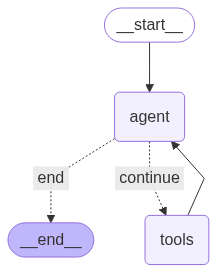

In [43]:
display(Image(app.get_graph().draw_mermaid_png()))

In [44]:
def printStream(stream):
    for s in stream:
        message = s["messages"][-1]
        if isinstance(message, tuple):
            print(message)
        else:
            message.pretty_print()

In [45]:
inputs = {"messages": {"role": "user", "content": "Add 3 and 4. Add 34 and 21. Then, find the product and difference between the sum of these. Also, please tell a joke on cricket."}}
printStream(app.stream(inputs, stream_mode="values"))

================================ Human Message =================================

Add 3 and 4. Add 34 and 21. Then, find the product and difference between the sum of these. Also, please tell a joke on cricket.
Messages being sent to LLM: [HumanMessage(content='Add 3 and 4. Add 34 and 21. Then, find the product and difference between the sum of these. Also, please tell a joke on cricket.', additional_kwargs={}, response_metadata={}, id='68ce7333-e7de-479c-8531-d0e10e4da9cd')]


================================== Ai Message ==================================
Tool Calls:
  add (3d2c0c0e-757a-487d-9ece-c236e4ae107c)
 Call ID: 3d2c0c0e-757a-487d-9ece-c236e4ae107c
  Args:
    b: 4.0
    a: 3.0
  add (35226f38-868d-4617-9185-285e58ddaa2a)
 Call ID: 35226f38-868d-4617-9185-285e58ddaa2a
  Args:
    b: 21.0
    a: 34.0
================================= Tool Message =================================
Name: add

55
Messages being sent to LLM: [HumanMessage(content='Add 3 and 4. Add 34 and 21. Then, find the product and difference between the sum of these. Also, please tell a joke on cricket.', additional_kwargs={}, response_metadata={}, id='68ce7333-e7de-479c-8531-d0e10e4da9cd'), AIMessage(content='', additional_kwargs={'function_call': {'name': 'add', 'arguments': '{"b": 21.0, "a": 34.0}'}}, response_metadata={'prompt_feedback': {'block_reason': 0, 'safety_ratings': []}, 'finish_reason': 'STOP', 'model_name': 'gemini-2.0-flash', 'safety_ratings': []}, id='run--4163ad0c-